# Phân loại Điểm tín dụng (Credit Score) — EDA, Preprocessing, Random Forest & các mô hình so sánh

**Dataset**: `data/raw/Credit_Score_Clean.csv` — 31.711 dòng × 21 cột (20 đặc trưng + 1 nhãn), SHA-256 đã xác thực.

**Bài toán**: Phân loại đa lớp `Credit_Score` với 3 nhãn có thứ tự tự nhiên:

| Nhãn | Mã hoá | Số dòng | Tỷ lệ |
|---|---:|---:|---:|
| `Poor` | 0 | 4.430 | 13,97% |
| `Standard` | 1 | 19.730 | 62,22% |
| `Good` | 2 | 7.551 | 23,81% |

**Cấu trúc notebook** (theo `spec.md`):

| Giai đoạn | Nội dung |
|---|---|
| 1 | EDA: toàn vẹn dữ liệu, phân phối nhãn, biến phân loại, outliers, tương quan |
| 2 | Tiền xử lý chống rò rỉ: split 60/20/20 stratified, winsorize p99 học từ train, feature engineering, encode/scale |
| 3 | Mô hình thư viện: Logistic Regression, Decision Tree, Random Forest baseline + tuned (tune cả `class_weight`) |
| 4 | Random Forest tự viết bằng `NumPy` thuần (Weighted Gini, quantile splits) |
| 5 | Đánh giá đồng bộ trên tập test: Precision, Recall, F1-Score, ROC-AUC (One-vs-Rest) |

> Ghi chú: đây là dữ liệu đã được làm sạch sẵn, không còn `Customer_ID` / `Month`, nên chia ngẫu nhiên theo dòng là lựa chọn duy nhất; rủi ro trùng khách hàng giữa các tập được nêu ở phần kết luận.

In [1]:
# ******************************************************************
# Purpose: Nạp toàn bộ thư viện và các hằng số dùng chung cho pipeline
#          (EDA, tiền xử lý, huấn luyện, đánh giá).
# Inputs: None.
# Returns: None.
# Author: Sirinne
# last modified:
# ******************************************************************
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    auc,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)

RANDOM_SEED = 42
TARGET_COL = "Credit_Score"
CLASS_MAPPING = {"Poor": 0, "Standard": 1, "Good": 2}
CLASS_NAMES = ["Poor", "Standard", "Good"]
RATIO_EPSILON = 1e-5
WINSORIZE_QUANTILE = 0.99
WINSORIZE_COLUMNS = ["Annual_Income", "Num_of_Delayed_Payment"]

print("Đã import xong thư viện và hằng số.")

Đã import xong thư viện và hằng số.


## 1. EDA — Hiểu dữ liệu trước khi mô hình hoá

Mục tiêu: xác nhận dữ liệu đúng như tài liệu mô tả, phát hiện các điểm cần xử lý (outliers cực đoan, nhóm tuổi dưới 18, `NM` là giá trị hợp lệ chứ không phải `NaN`) và tìm các đặc trưng phân tách nhãn tốt nhất.

In [2]:
# ******************************************************************
# Purpose: Xác định thư mục gốc của dự án từ vị trí đang chạy để mọi
#          đường dẫn dữ liệu/kết quả đều là đường dẫn tuyệt đối ổn định.
# Inputs: start_path: thư mục bắt đầu tìm kiếm (mặc định là cwd).
# Returns: Path của thư mục gốc chứa đồng thời data/ và source/.
# Author: Sirinne
# last modified:
# ******************************************************************
def resolve_project_root(start_path=None):
    current = (start_path or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "data").is_dir() and (candidate / "source").is_dir():
            return candidate
    raise FileNotFoundError("Không tìm thấy thư mục gốc chứa data/ và source/.")


# ******************************************************************
# Purpose: Ghi một dòng thông điệp ra cả màn hình notebook và file log
#          của lần chạy hiện tại để toàn bộ quá trình có thể truy vết.
# Inputs: message: nội dung thông điệp cần ghi (chuỗi một dòng).
# Returns: None.
# Author: Sirinne
# last modified:
# ******************************************************************
def log_message(message):
    print(message)
    with LOG_PATH.open("a", encoding="utf-8") as log_handle:
        log_handle.write(f"{message}\n")


PROJECT_ROOT = resolve_project_root()
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Credit_Score_Clean.csv"
RESULTS_RUN_DIR = PROJECT_ROOT / "results" / "run"
RESULTS_VISUALIZE_DIR = PROJECT_ROOT / "results" / "visualize"
LOG_DIR = PROJECT_ROOT / "source" / "logs"

for directory in (RESULTS_RUN_DIR, RESULTS_VISUALIZE_DIR, LOG_DIR):
    directory.mkdir(parents=True, exist_ok=True)

LOG_PATH = LOG_DIR / f"train_credit_score_rf_{time.strftime('%Y%m%d_%H%M%S')}.txt"
log_message(f"Log: {LOG_PATH.relative_to(PROJECT_ROOT)}")
log_message(f"Data: {DATA_PATH.relative_to(PROJECT_ROOT)}")

df_raw = pd.read_csv(DATA_PATH)

Log: source\logs\train_credit_score_rf_20261114_085109.txt
Data: data\raw\Credit_Score_Clean.csv


In [3]:
# ******************************************************************
# Purpose: Kiểm tra toàn vẹn dữ liệu trước khi phân tích: kích thước,
#          missing, trùng lặp, giá trị vô cực và ép kiểu cột đếm.
# Inputs: df_raw: DataFrame đọc trực tiếp từ CSV.
# Returns: None (in báo cáo và ghi log).
# Author: Sirinne
# last modified:
# ******************************************************************
numeric_columns = df_raw.select_dtypes(include="number").columns.tolist()

assert df_raw.shape == (31711, 21), df_raw.shape
assert TARGET_COL in df_raw.columns
assert int(df_raw.isna().sum().sum()) == 0
assert int(df_raw.duplicated().sum()) == 0
assert int(np.isinf(df_raw[numeric_columns]).sum().sum()) == 0
assert set(df_raw[TARGET_COL].unique()) == set(CLASS_NAMES)

# Num_Credit_Inquiries đọc là float nhưng toàn bộ là số nguyên -> ép int
assert np.allclose(df_raw["Num_Credit_Inquiries"] % 1, 0)
df_raw["Num_Credit_Inquiries"] = df_raw["Num_Credit_Inquiries"].astype(int)

quality_report = pd.DataFrame(
    {
        "dtype": df_raw.dtypes.astype(str),
        "distinct": df_raw.nunique(),
        "min": df_raw[numeric_columns].min(),
        "max": df_raw[numeric_columns].max(),
    }
)

log_message("Dữ liệu hợp lệ: 31.711 x 21, 0 missing, 0 duplicate, 0 +/-inf.")
print("Số dòng Age < 18:", int((df_raw["Age"] < 18).sum()))
print("Số dòng Credit_History_Age_Months == 0:", int((df_raw["Credit_History_Age_Months"] == 0).sum()))
display(quality_report)

Dữ liệu hợp lệ: 31.711 x 21, 0 missing, 0 duplicate, 0 +/-inf.
Số dòng Age < 18: 956
Số dòng Credit_History_Age_Months == 0: 2863


,dtype,distinct,min,max
Age,int64,43,14.000000,5.600000e+01
Amount_invested_monthly,float64,28957,0.000000,1.903080e+03
Annual_Income,float64,7743,7006.520000,2.419806e+07
Changed_Credit_Limit,float64,2620,0.000000,2.690000e+01
Credit_History_Age_Months,int64,345,0.000000,4.040000e+02
Credit_Mix,str,3,NaN,NaN
Credit_Score,str,3,NaN,NaN
Credit_Utilization_Ratio,float64,31711,20.832487,4.956452e+01
Delay_from_due_date,int64,61,0.000000,6.000000e+01
Interest_Rate,int64,34,1.000000,3.400000e+01


Tỷ lệ mất cân bằng (Standard/Poor): 4.45x


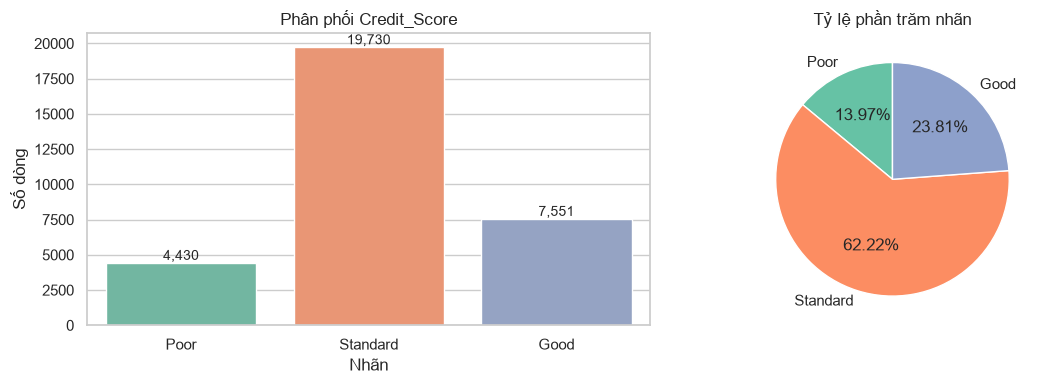

,count,percentage
Credit_Score,,
Poor,4430,13.9699
Standard,19730,62.2182
Good,7551,23.8119


In [4]:
# ******************************************************************
# Purpose: Phân tích phân phối biến mục tiêu Credit_Score (số lượng,
#          tỷ lệ, mức độ mất cân bằng) và vẽ biểu đồ lưu vào results.
# Inputs: df_raw: DataFrame gốc.
# Returns: DataFrame target_summary (count, percentage).
# Author: Sirinne
# last modified:
# ******************************************************************
target_counts = df_raw[TARGET_COL].value_counts().reindex(CLASS_NAMES)
target_summary = pd.DataFrame(
    {
        "count": target_counts.astype(int),
        "percentage": (target_counts / len(df_raw) * 100).round(4),
    }
)
imbalance_ratio = target_counts.max() / target_counts.min()
log_message(f"Tỷ lệ mất cân bằng (Standard/Poor): {imbalance_ratio:.2f}x")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=TARGET_COL, data=df_raw, order=CLASS_NAMES, hue=TARGET_COL,
              hue_order=CLASS_NAMES, legend=False, palette="Set2", ax=axes[0])
axes[0].set_title("Phân phối Credit_Score")
axes[0].set_xlabel("Nhãn")
axes[0].set_ylabel("Số dòng")
for patch, value in zip(axes[0].patches, target_counts.values):
    axes[0].annotate(f"{value:,}", (patch.get_x() + patch.get_width() / 2, value),
                     ha="center", va="bottom", fontsize=10)

axes[1].pie(target_counts.values, labels=target_counts.index, autopct="%1.2f%%",
            colors=sns.color_palette("Set2", 3), startangle=90)
axes[1].set_title("Tỷ lệ phần trăm nhãn")

plt.tight_layout()
plt.savefig(RESULTS_VISUALIZE_DIR / "eda_target_distribution.png", dpi=150)
plt.show()

display(target_summary)

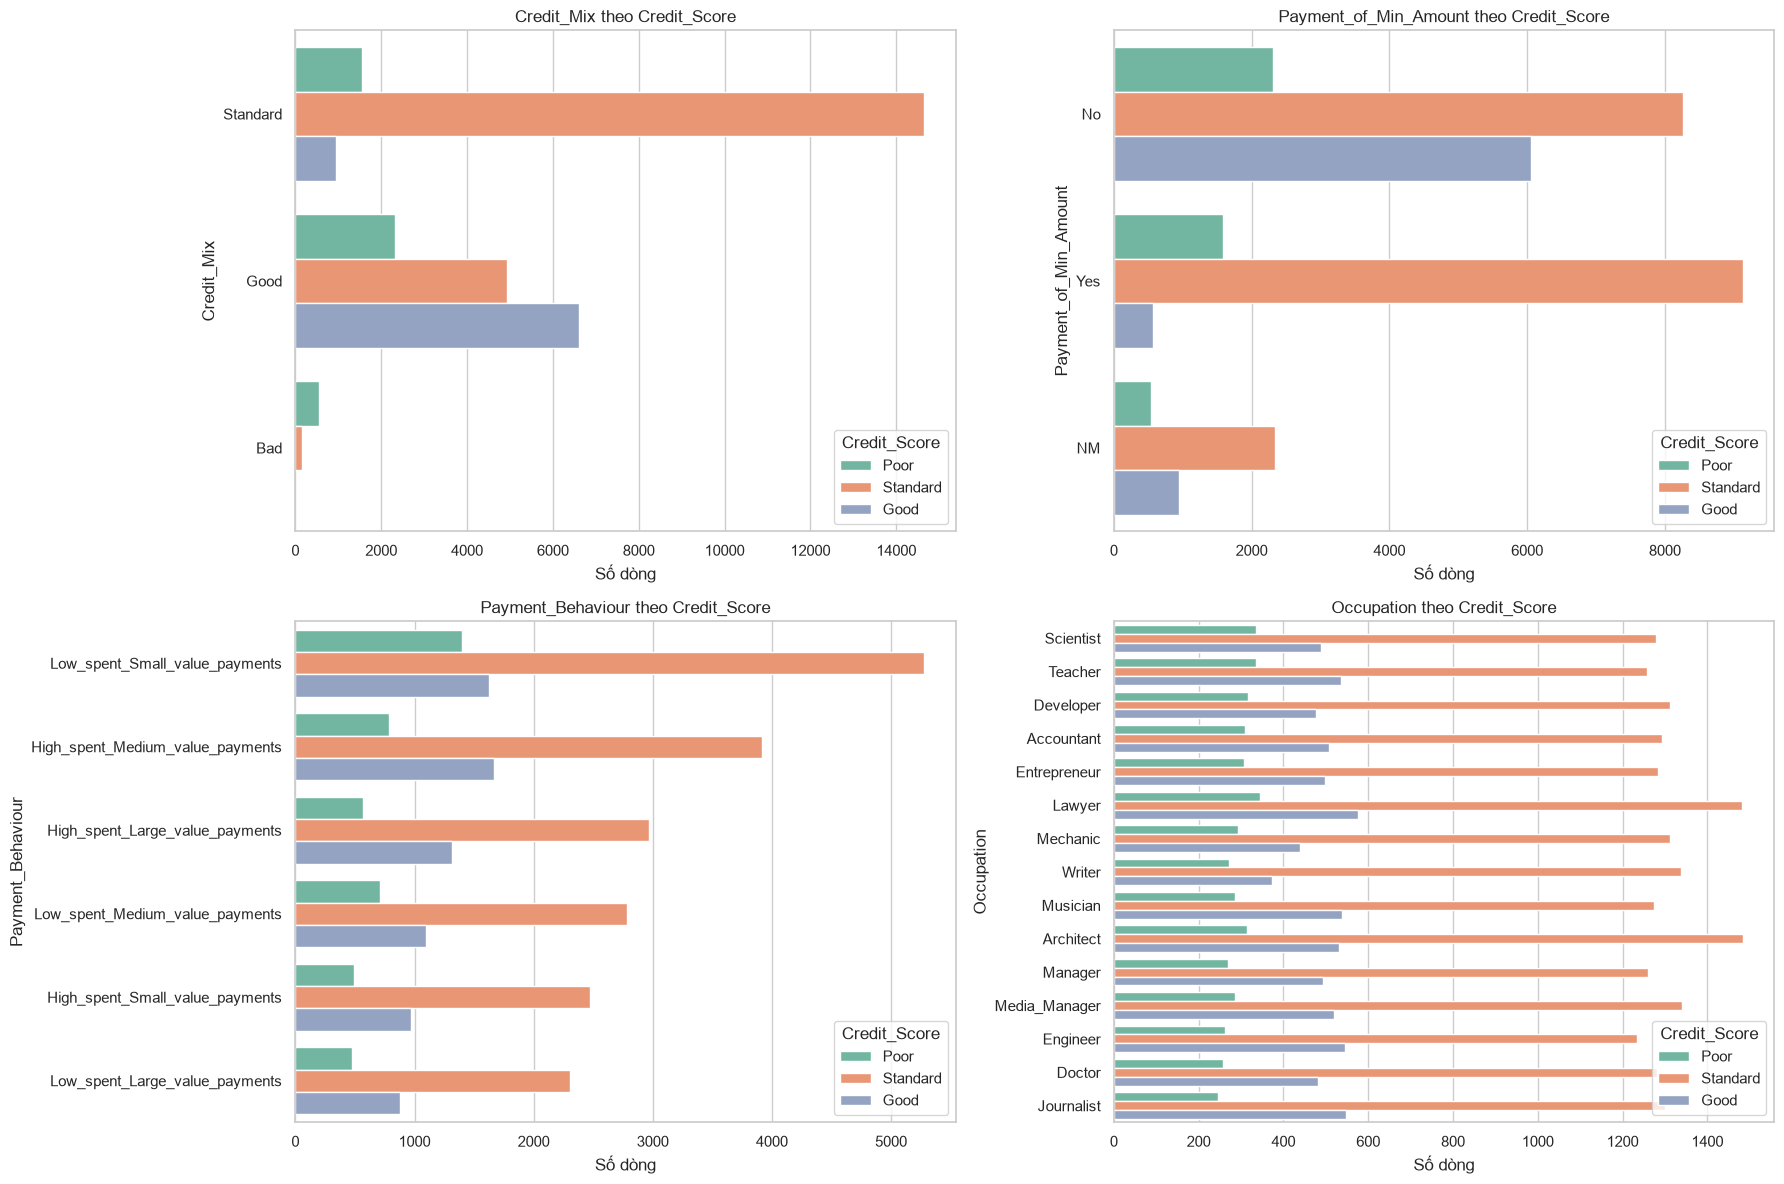

--- Tỷ lệ nhãn trong từng nhóm Credit_Mix ---


Credit_Score,Poor,Standard,Good
Credit_Mix,,,
Bad,0.7894,0.2106,0.0000
Good,0.1675,0.3557,0.4768
Standard,0.0907,0.8547,0.0546


--- Tỷ lệ nhãn trong từng nhóm Payment_of_Min_Amount ---


Credit_Score,Poor,Standard,Good
Payment_of_Min_Amount,,,
NM,0.1417,0.6124,0.2458
No,0.1389,0.4971,0.3640
Yes,0.1401,0.8101,0.0498


--- Tỷ lệ nhãn trong từng nhóm Payment_Behaviour ---


Credit_Score,Poor,Standard,Good
Payment_Behaviour,,,
High_spent_Large_value_payments,0.1170,0.6118,0.2712
High_spent_Medium_value_payments,0.1237,0.6147,0.2616
High_spent_Small_value_payments,0.1249,0.6286,0.2465
Low_spent_Large_value_payments,0.1289,0.6305,0.2406
Low_spent_Medium_value_payments,0.1551,0.6069,0.2380
Low_spent_Small_value_payments,0.1685,0.6357,0.1958


--- Tỷ lệ nhãn trong từng nhóm Occupation ---


Credit_Score,Poor,Standard,Good
Occupation,,,
Accountant,0.1468,0.6130,0.2402
Architect,0.1349,0.6370,0.2281
Developer,0.1506,0.6228,0.2266
Doctor,0.1276,0.6340,0.2384
Engineer,0.1278,0.6048,0.2674
Entrepreneur,0.1466,0.6149,0.2385
Journalist,0.1175,0.6206,0.2618
Lawyer,0.1437,0.6168,0.2395
Manager,0.1330,0.6231,0.2438


In [5]:
# ******************************************************************
# Purpose: So sánh tỷ lệ 3 nhãn Credit_Score theo từng biến phân loại
#          để phát hiện nhóm có rủi ro tín dụng cao.
# Inputs: df_raw: DataFrame gốc.
# Returns: None (hiển thị 4 biểu đồ và lưu vào results/visualize).
# Author: Sirinne
# last modified:
# ******************************************************************
categorical_features = ["Credit_Mix", "Payment_of_Min_Amount", "Payment_Behaviour", "Occupation"]

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
for ax, feature in zip(axes.ravel(), categorical_features):
    if feature == "Occupation":
        # Sắp xếp theo tỷ lệ Poor giảm dần để biểu đồ dài dễ đọc
        order = (
            df_raw.groupby(feature)[TARGET_COL]
            .apply(lambda labels: (labels == "Poor").mean())
            .sort_values(ascending=False)
            .index
        )
    else:
        order = df_raw[feature].value_counts().index

    sns.countplot(y=feature, hue=TARGET_COL, data=df_raw, order=order,
                  hue_order=CLASS_NAMES, palette="Set2", ax=ax)
    ax.set_title(f"{feature} theo Credit_Score")
    ax.set_xlabel("Số dòng")
    ax.set_ylabel(feature)
    ax.legend(title="Credit_Score", loc="lower right")

plt.tight_layout()
plt.savefig(RESULTS_VISUALIZE_DIR / "eda_categorical_vs_target.png", dpi=150)
plt.show()

for feature in categorical_features:
    share = (
        pd.crosstab(df_raw[feature], df_raw[TARGET_COL], normalize="index")
        .reindex(columns=CLASS_NAMES)
        .round(4)
    )
    print(f"--- Tỷ lệ nhãn trong từng nhóm {feature} ---")
    display(share)

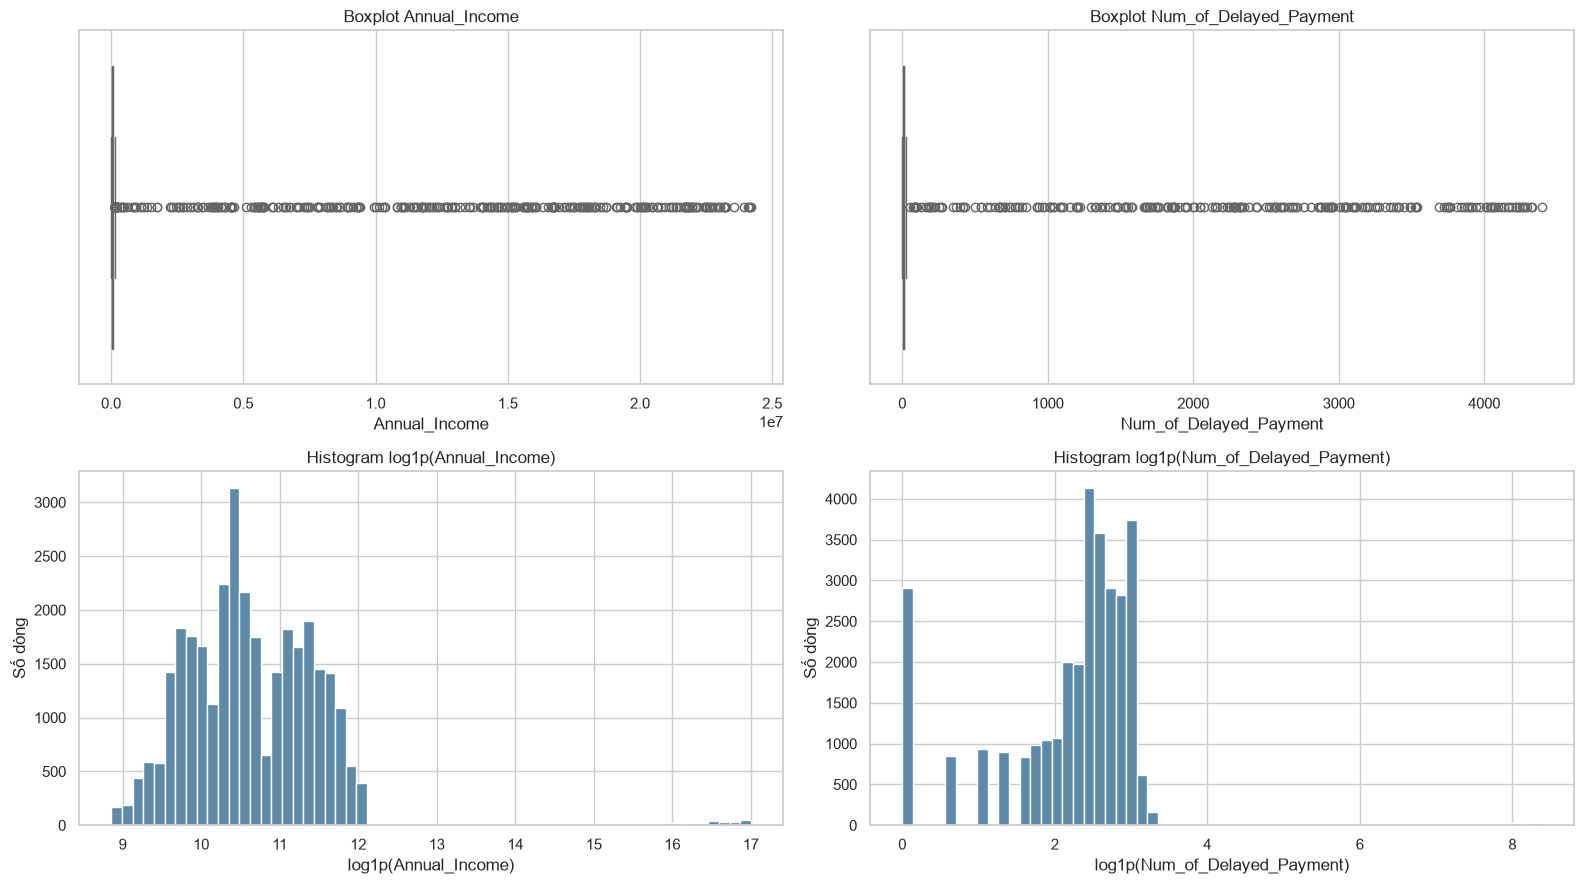

Credit_Score,Poor,Standard,Good,range
Annual_Income,37107.79,35733.63,40639.06,4905.43
Outstanding_Debt,1010.20,768.74,715.01,295.19
Credit_History_Age_Months,233.00,249.00,281.00,48.00
Monthly_Balance,361.43,364.86,386.18,24.75
Amount_invested_monthly,120.56,118.70,130.32,11.62
Delay_from_due_date,18.00,15.00,10.00,8.00
Total_EMI_per_month,50.24,45.84,45.04,5.20
Interest_Rate,10.00,11.00,7.00,4.00
Num_of_Delayed_Payment,10.00,12.00,8.00,4.00
Age,34.00,34.00,37.00,3.00


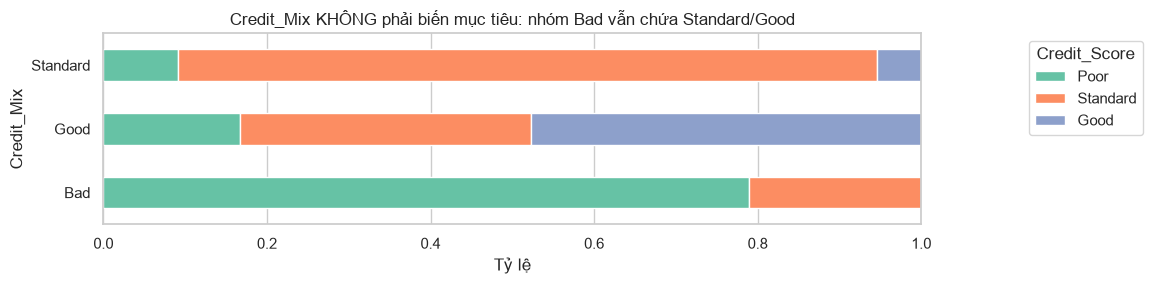

In [6]:
# ******************************************************************
# Purpose: Khảo sát phân phối của các biến số lệch phải (Annual_Income,
#          Num_of_Delayed_Payment), nhóm tuổi dưới 18 và tương quan giữa
#          các biến số để định hướng xử lý outlier.
# Inputs: df_raw: DataFrame gốc.
# Returns: None (hiển thị biểu đồ + heatmap).
# Author: Sirinne
# last modified:
# ******************************************************************
skewed_features = ["Annual_Income", "Num_of_Delayed_Payment"]

fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for column, ax in zip(skewed_features, axes[0]):
    sns.boxplot(x=df_raw[column], ax=ax, color="#7fb3d5")
    ax.set_title(f"Boxplot {column}")
    ax.set_xlabel(column)

for column, ax in zip(skewed_features, axes[1]):
    ax.hist(np.log1p(df_raw[column]), bins=60, color="#5d8aa8")
    ax.set_title(f"Histogram log1p({column})")
    ax.set_xlabel(f"log1p({column})")
    ax.set_ylabel("Số dòng")

plt.tight_layout()
plt.savefig(RESULTS_VISUALIZE_DIR / "eda_numeric_outliers.png", dpi=150)
plt.show()

numeric_columns = df_raw.select_dtypes(include="number").columns.tolist()
median_by_class = df_raw.groupby(TARGET_COL)[numeric_columns].median().T.infer_objects()
median_by_class = median_by_class.reindex(columns=CLASS_NAMES).astype(float).round(2)
median_by_class["range"] = (median_by_class.max(axis=1) - median_by_class.min(axis=1)).round(2)
display(median_by_class.sort_values("range", ascending=False).head(12))

fig, ax = plt.subplots(figsize=(12, 3))
bad_share = (
    pd.crosstab(df_raw["Credit_Mix"], df_raw[TARGET_COL], normalize="index")
    .reindex(columns=CLASS_NAMES)
)
bad_share.plot(kind="barh", stacked=True, ax=ax, color=sns.color_palette("Set2", 3))
ax.set_title("Credit_Mix KHÔNG phải biến mục tiêu: nhóm Bad vẫn chứa Standard/Good")
ax.set_xlabel("Tỷ lệ")
ax.legend(title="Credit_Score", loc="upper right", bbox_to_anchor=(1.28, 1))
plt.tight_layout()
plt.savefig(RESULTS_VISUALIZE_DIR / "eda_credit_mix_vs_target.png", dpi=150)
plt.show()

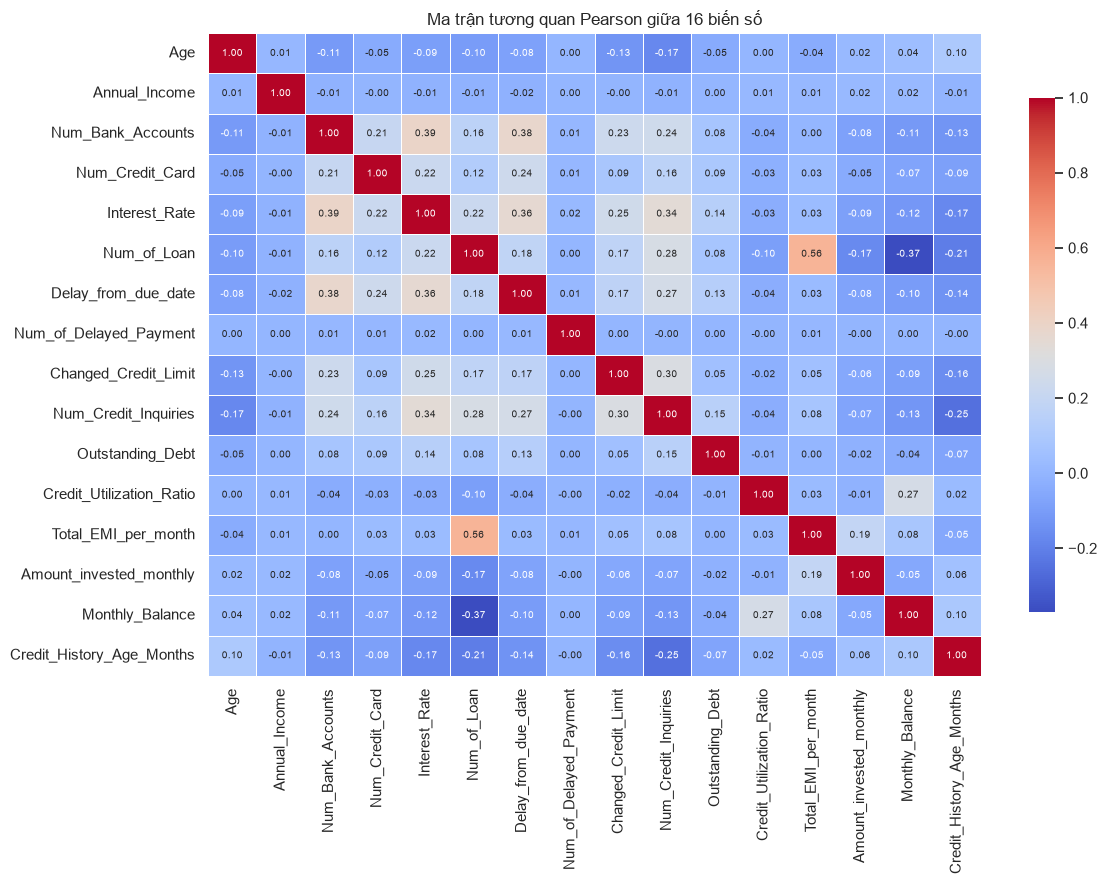

Các cặp biến tương quan |r| >= 0.5: {('Num_of_Loan', 'Total_EMI_per_month'): 0.5589048706989788}


In [7]:
# ******************************************************************
# Purpose: Vẽ ma trận tương quan của 16 biến số (Pearson) để tìm các
#          cặp đặc trưng trùng lặp thông tin và mối liên hệ với nhãn.
# Inputs: df_raw: DataFrame gốc.
# Returns: None (hiển thị heatmap).
# Author: Sirinne
# last modified:
# ******************************************************************
correlation_matrix = df_raw.select_dtypes(include="number").corr()

plt.figure(figsize=(12, 9))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm",
            linewidths=0.4, cbar_kws={"shrink": 0.8}, annot_kws={"size": 7})
plt.title("Ma trận tương quan Pearson giữa 16 biến số")
plt.tight_layout()
plt.savefig(RESULTS_VISUALIZE_DIR / "eda_correlation_heatmap.png", dpi=150)
plt.show()

high_correlation_pairs = (
    correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
    .stack()
    .loc[lambda values: values.abs() >= 0.5]
    .sort_values(ascending=False)
)
log_message(f"Các cặp biến tương quan |r| >= 0.5: {high_correlation_pairs.to_dict()}")

### Nhận xét EDA

1. **Dữ liệu đã sạch hoàn toàn**: 31.711 dòng × 21 cột, không `NaN`, không trùng lặp, không `+/-inf`. `Num_Credit_Inquiries` được đọc như `float` nhưng bản chất là số nguyên → ép kiểu `int` là an toàn.
2. **Mất cân bằng lớp vừa phải** (`Standard` gấp ~4,45 lần `Poor`): Accuracy không đủ để đánh giá. Một mô hình dự đoán toàn `Standard` đã đạt ~62,2% accuracy và **0 điểm F1** cho hai lớp còn lại. Do đó mọi bước tuning của đồ thị sẽ dùng **Macro F1** (đối xử bình đẳng 3 lớp) và báo cáo thêm **Weighted F1**, **Precision/Recall từng lớp**, **ROC-AUC OvR**.
3. **`NM` trong `Payment_of_Min_Amount` là nhóm có nghĩa** (12,06%), không phải missing → giữ thành một category riêng, không quy về nhóm khác.
4. **`Credit_Mix` không phải nhãn**: nhóm `Bad` (698 dòng) vẫn chứa cả `Standard` (147 dòng) và các nhãn khác; không được dùng như biến mục tiêu thay thế.
5. **Outliers thật nhưng ít thông tin**: `Annual_Income` (max 24,2M so với p99 ~179k) và `Num_of_Delayed_Payment` (max 4.397 so với p75 = 15) lệch phải cực mạnh → thanh lý bằng **winsorize p99 học từ tập train**. `Age < 18` (956 dòng) và `Credit_History_Age_Months = 0` (2.863 dòng) là bất thường về mặt nghiệp vụ nhưng vẫn giữ lại (dataset đã được làm sạch có chủ đích), thay vào đó thêm **cờ nhị phân** để cây có thể tự tách nhóm nếu nhóm này thực sự khác biệt.
6. Các biến `Interest_Rate`, `Delay_from_due_date`, `Outstanding_Debt`, `Credit_History_Age_Months` có trung vị chênh lệch rõ giữa 3 nhãn → kỳ vọng các mô hình dựa trên cây (RF) khai thác tốt các ngưỡng cắt rời rạc này hơn Logistic Regression.

## 2. Tiền xử lý & Feature Engineering (chống rò rỉ dữ liệu)

Mọi tham số học từ dữ liệu (ngưỡng winsorize, scaler, encoder) **chỉ được fit trên tập train**, sau đó áp dụng nguyên trạng cho validation và test:

| Bước | Chi tiết |
|---|---|
| Chia tập | Stratified 60 / 20 / 20, `random_state=42` |
| Outliers | Winsorize tại **p99 của train** cho `Annual_Income`, `Num_of_Delayed_Payment` (giữ `Annual_Income` max 24,2M như một tín hiệu "thu nhập cực cao") |
| Cờ nghiệp vụ | `is_under_18`, `has_no_credit_history` (giữ nguyên 956 dòng tuổi 14–17, 2.863 dòng lịch sử tín dụng = 0) |
| Tỷ lệ | `debt_to_income_ratio`, `annual_emi_to_income_ratio`, `annual_investment_to_income_ratio`, `balance_to_debt_ratio` |
| Tổng hợp | `total_financial_accounts`, `delay_severity_score` |
| Ordinal | `Credit_Mix`: Bad/Standard/Good → 0/1/2; `Payment_Behaviour` → `spending_level` + `payment_value_tier` |
| Encoding | One-Hot `Occupation`, `Payment_of_Min_Amount`, `Payment_Behaviour` (`handle_unknown="ignore"`, fit trên train) |
| Scaling | `StandardScaler` chỉ cho Logistic Regression; cây quyết định dùng ma trận thô |

In [8]:
# ******************************************************************
# Purpose: Mã hoá nhãn theo đúng thứ tự tín dụng và chia dữ liệu thành
#          3 tập stratified 60/20/20 mà không làm rò rỉ thông tin.
# Inputs: df_raw: DataFrame gốc.
# Returns: None (tạo x_train_raw, x_val_raw, x_test_raw, y_train,
#          y_val, y_test ở phạm vi notebook).
# Author: Sirinne
# last modified:
# ******************************************************************
df_model = df_raw.copy()
df_model[TARGET_COL] = df_model[TARGET_COL].map(CLASS_MAPPING)
assert df_model[TARGET_COL].notna().all(), "Nhãn lạ không có trong CLASS_MAPPING"

target = df_model.pop(TARGET_COL)
x_train_raw, x_temp_raw, y_train, y_temp = train_test_split(
    df_model, target, test_size=0.4, stratify=target, random_state=RANDOM_SEED
)
x_val_raw, x_test_raw, y_val, y_test = train_test_split(
    x_temp_raw, y_temp, test_size=0.5, stratify=y_temp, random_state=RANDOM_SEED
)

y_train = y_train.to_numpy(dtype=np.int64)
y_val = y_val.to_numpy(dtype=np.int64)
y_test = y_test.to_numpy(dtype=np.int64)

assert (len(x_train_raw), len(x_val_raw), len(x_test_raw)) == (19026, 6342, 6343)
log_message(f"Train: {x_train_raw.shape} | Val: {x_val_raw.shape} | Test: {x_test_raw.shape}")
print("Tỷ lệ nhãn train:", np.bincount(y_train) / len(y_train))
print("Tỷ lệ nhãn val  :", np.bincount(y_val) / len(y_val))
print("Tỷ lệ nhãn test :", np.bincount(y_test) / len(y_test))

Train: (19026, 20) | Val: (6342, 20) | Test: (6343, 20)
Tỷ lệ nhãn train: [0.13970356 0.6222012  0.23809524]
Tỷ lệ nhãn val  : [0.13970356 0.6222012  0.23809524]
Tỷ lệ nhãn test : [0.13968154 0.62210311 0.23821536]


In [9]:
# ******************************************************************
# Purpose: Học ngưỡng winsorize p99 trên tập train cho các biến lệch
#          phải cực đoan, sau đó dùng lại ngưỡng này cho val/test.
# Inputs: frame: dữ liệu nguồn chứa các cột cần tính ngưỡng.
#         column_names: danh sách cột cần tính ngưỡng.
#         quantile: phân vị dùng làm ngưỡng trên (mặc định 0.99).
# Returns: dict {tên_cột: ngưỡng_trên} tính trên frame.
# Author: Sirinne
# last modified:
# ******************************************************************
def compute_upper_bounds(frame, column_names, quantile=WINSORIZE_QUANTILE):
    return {column: float(frame[column].quantile(quantile)) for column in column_names}


# ******************************************************************
# Purpose: Cắt (clip) các giá trị vượt ngưỡng đã học về đúng ngưỡng,
#          không thay đổi giá trị hợp lệ và không sửa DataFrame gốc.
# Inputs: frame: dữ liệu cần cắt.
#         bounds: dict {tên_cột: ngưỡng_trên} lấy từ tập train.
# Returns: DataFrame mới đã được winsorize.
# Author: Sirinne
# last modified:
# ******************************************************************
def clip_extreme_values(frame, bounds):
    clipped = frame.copy()
    for column, upper_bound in bounds.items():
        clipped[column] = clipped[column].clip(upper=upper_bound)
    return clipped


# ******************************************************************
# Purpose: Tạo toàn bộ đặc trưng nghiệp vụ tín dụng (tỷ lệ thu nhập,
#          tổng hợp tài khoản, cờ bất thường, tách Payment_Behaviour)
#          theo cùng một công thức cho train/val/test.
# Inputs: frame: DataFrame đã được winsorize.
# Returns: DataFrame mới với các cột đặc trưng được bổ sung/sửa đổi.
# Author: Sirinne
# last modified:
# ******************************************************************
def build_engineered_features(frame):
    engineered = frame.copy()

    engineered["Credit_Mix"] = engineered["Credit_Mix"].map({"Bad": 0, "Standard": 1, "Good": 2})
    behaviour_tokens = engineered["Payment_Behaviour"].str.split("_")
    engineered["spending_level"] = behaviour_tokens.str[0].map({"Low": 0, "High": 1})
    engineered["payment_value_tier"] = behaviour_tokens.str[2].map({"Small": 0, "Medium": 1, "Large": 2})
    assert engineered[["Credit_Mix", "spending_level", "payment_value_tier"]].notna().all().all()

    engineered["is_under_18"] = (engineered["Age"] < 18).astype(int)
    engineered["has_no_credit_history"] = (engineered["Credit_History_Age_Months"] == 0).astype(int)

    engineered["debt_to_income_ratio"] = engineered["Outstanding_Debt"] / (engineered["Annual_Income"] + RATIO_EPSILON)
    engineered["annual_emi_to_income_ratio"] = (engineered["Total_EMI_per_month"] * 12.0) / (engineered["Annual_Income"] + RATIO_EPSILON)
    engineered["annual_investment_to_income_ratio"] = (engineered["Amount_invested_monthly"] * 12.0) / (engineered["Annual_Income"] + RATIO_EPSILON)
    engineered["balance_to_debt_ratio"] = engineered["Monthly_Balance"] / (engineered["Outstanding_Debt"] + RATIO_EPSILON)
    engineered["total_financial_accounts"] = (
        engineered["Num_Bank_Accounts"] + engineered["Num_Credit_Card"] + engineered["Num_of_Loan"]
    )
    engineered["delay_severity_score"] = engineered["Delay_from_due_date"] * np.log1p(engineered["Num_of_Delayed_Payment"])
    return engineered


winsorize_bounds = compute_upper_bounds(x_train_raw, WINSORIZE_COLUMNS)
log_message(f"Ngưỡng winsorize p99 (train): {winsorize_bounds}")

x_train = build_engineered_features(clip_extreme_values(x_train_raw, winsorize_bounds))
x_val = build_engineered_features(clip_extreme_values(x_val_raw, winsorize_bounds))
x_test = build_engineered_features(clip_extreme_values(x_test_raw, winsorize_bounds))

# Kiểm tra ngưỡng thực sự chặn được đuôi phân phối mà không xoá dòng nào
assert x_train["Annual_Income"].max() <= winsorize_bounds["Annual_Income"]
assert x_val["Num_of_Delayed_Payment"].max() <= winsorize_bounds["Num_of_Delayed_Payment"]
assert x_test["Num_of_Delayed_Payment"].max() <= winsorize_bounds["Num_of_Delayed_Payment"]
log_message(f"Số đặc trưng sau feature engineering: {x_train.shape[1]}")

Ngưỡng winsorize p99 (train): {'Annual_Income': 179317.04, 'Num_of_Delayed_Payment': 25.0}
Số đặc trưng sau feature engineering: 30


In [10]:
# ******************************************************************
# Purpose: Dựng ColumnTransformer (biến số + one-hot biến danh mục) với
#          một lựa chọn biến đổi số, dùng chung cho mọi mô hình.
# Inputs: numeric_columns: list tên cột số/ordinal.
#         categorical_columns: list tên cột danh mục cần one-hot.
#         numeric_transformer: "passthrough" hoặc StandardScaler().
# Returns: ColumnTransformer chưa fit, xuất ra DataFrame giữ tên cột.
# Author: Sirinne
# last modified:
# ******************************************************************
def build_preprocessor(numeric_columns, categorical_columns, numeric_transformer):
    return ColumnTransformer(
        [
            ("numeric", numeric_transformer, numeric_columns),
            ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_columns),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")


categorical_columns = ["Occupation", "Payment_of_Min_Amount", "Payment_Behaviour"]
numeric_columns = [column for column in x_train.columns if column not in categorical_columns]

# Logistic Regression cần scale; cây quyết định giữ nguyên giá trị gốc
linear_preprocessor = build_preprocessor(numeric_columns, categorical_columns, StandardScaler())
tree_preprocessor = build_preprocessor(numeric_columns, categorical_columns, "passthrough")

X_train_linear = linear_preprocessor.fit_transform(x_train)
X_val_linear = linear_preprocessor.transform(x_val)
X_test_linear = linear_preprocessor.transform(x_test)

X_train_tree = tree_preprocessor.fit_transform(x_train)
X_val_tree = tree_preprocessor.transform(x_val)
X_test_tree = tree_preprocessor.transform(x_test)

assert list(X_train_linear.columns) == list(X_val_linear.columns) == list(X_test_linear.columns)
assert list(X_train_tree.columns) == list(X_val_tree.columns) == list(X_test_tree.columns)
assert not X_train_linear.isna().any().any() and not X_train_tree.isna().any().any()
assert X_train_linear.shape[1] == X_train_tree.shape[1]
assert np.isfinite(X_train_linear.to_numpy()).all()

log_message(f"Số đặc trưng sau encode: {X_train_linear.shape[1]}")
print(f"Linear matrix: {X_train_linear.shape} | Val: {X_val_linear.shape} | Test: {X_test_linear.shape}")

Số đặc trưng sau encode: 51
Linear matrix: (19026, 51) | Val: (6342, 51) | Test: (6343, 51)


## 3. Mô hình thư viện (Scikit-Learn)

Nguyên tắc chọn mô hình: **chỉ dùng validation để chọn cấu hình**, test được "niêm phong" đến bước đánh giá cuối. Tiêu chí chọn là **Macro F1** (mỗi lớp có trọng số như nhau), vì Accuracy sẽ bị lớp `Standard` chi phối.

In [11]:
# ******************************************************************
# Purpose: Huấn luyện 2 cấu hình Logistic Regression (không cân bằng và
#          class_weight='balanced') trên dữ liệu đã scale, so sánh Macro F1
#          trên validation để chọn cấu hình.
# Inputs: X_train_linear, y_train, X_val_linear, y_val.
# Returns: logistic_model (đã fit), logistic_candidates (dict thông tin).
# Author: Sirinne
# last modified:
# ******************************************************************
logistic_candidates = {}
for configuration_name, class_weight in {"none": None, "balanced": "balanced"}.items():
    started_at = time.perf_counter()
    candidate_model = LogisticRegression(
        max_iter=2000, class_weight=class_weight, random_state=RANDOM_SEED
    )
    candidate_model.fit(X_train_linear, y_train)
    fit_seconds = time.perf_counter() - started_at

    validation_macro_f1 = f1_score(
        y_val, candidate_model.predict(X_val_linear), average="macro"
    )
    logistic_candidates[configuration_name] = {
        "model": candidate_model,
        "fit_seconds": fit_seconds,
        "validation_macro_f1": validation_macro_f1,
    }
    log_message(
        f"LogisticRegression[class_weight={configuration_name}] "
        f"val macro F1 = {validation_macro_f1:.4f} ({fit_seconds:.2f}s)"
    )

best_logistic_name = max(
    logistic_candidates, key=lambda name: logistic_candidates[name]["validation_macro_f1"]
)
logistic_model = logistic_candidates[best_logistic_name]["model"]
log_message(f"Chọn Logistic Regression: class_weight={best_logistic_name}")

LogisticRegression[class_weight=none] val macro F1 = 0.5687 (0.08s)
LogisticRegression[class_weight=balanced] val macro F1 = 0.5842 (0.08s)
Chọn Logistic Regression: class_weight=balanced


In [12]:
# ******************************************************************
# Purpose: Dò max_depth và class_weight cho Decision Tree trên validation
#          để có baseline cây đơn lẻ công bằng với các mô hình ensemble.
# Inputs: X_train_tree, y_train, X_val_tree, y_val.
# Returns: decision_tree_model (đã fit), decision_tree_candidates (dict).
# Author: Sirinne
# last modified:
# ******************************************************************
decision_tree_candidates = {}
for max_depth in [8, 12, 16, 20, None]:
    for class_weight in [None, "balanced"]:
        configuration_name = f"depth={max_depth}|class_weight={class_weight}"
        started_at = time.perf_counter()
        candidate_model = DecisionTreeClassifier(
            max_depth=max_depth, class_weight=class_weight,
            min_samples_leaf=2, random_state=RANDOM_SEED,
        )
        candidate_model.fit(X_train_tree, y_train)
        fit_seconds = time.perf_counter() - started_at

        validation_macro_f1 = f1_score(
            y_val, candidate_model.predict(X_val_tree), average="macro"
        )
        decision_tree_candidates[configuration_name] = {
            "model": candidate_model,
            "fit_seconds": fit_seconds,
            "validation_macro_f1": validation_macro_f1,
        }

best_tree_name = max(
    decision_tree_candidates, key=lambda name: decision_tree_candidates[name]["validation_macro_f1"]
)
decision_tree_model = decision_tree_candidates[best_tree_name]["model"]
log_message(
    f"Decision Tree tốt nhất: {best_tree_name} "
    f"val macro F1 = {decision_tree_candidates[best_tree_name]['validation_macro_f1']:.4f}"
)
display(
    pd.DataFrame(
        {
            name: {"val_macro_f1": result["validation_macro_f1"], "fit_seconds": result["fit_seconds"]}
            for name, result in decision_tree_candidates.items()
        }
    ).T.round(4)
)

Decision Tree tốt nhất: depth=16|class_weight=None val macro F1 = 0.6540


,val_macro_f1,fit_seconds
depth=8|class_weight=None,0.6422,0.1545
depth=8|class_weight=balanced,0.6380,0.1535
depth=12|class_weight=None,0.6472,0.2089
depth=12|class_weight=balanced,0.6354,0.2171
depth=16|class_weight=None,0.6540,0.2612
depth=16|class_weight=balanced,0.6430,0.2695
depth=20|class_weight=None,0.6418,0.2965
depth=20|class_weight=balanced,0.6282,0.2811
depth=None|class_weight=None,0.6214,0.3531
depth=None|class_weight=balanced,0.6274,0.2921


In [13]:
# ******************************************************************
# Purpose: Huấn luyện Random Forest baseline không cân bằng lớp, sau đó
#          tìm siêu tham số + trọng số lớp tốt nhất bằng RandomizedSearchCV
#          trên lưới Macro F1 (5-fold stratified, 20 tổ hợp).
# Inputs: X_train_tree, y_train, X_val_tree, y_val.
# Returns: random_forest_baseline, random_forest_tuned, random_search,
#          random_forest_search_seconds.
# Author: Sirinne
# last modified:
# ******************************************************************
random_forest_baseline = RandomForestClassifier(
    n_estimators=100, random_state=RANDOM_SEED, n_jobs=-1
)
started_at = time.perf_counter()
random_forest_baseline.fit(X_train_tree, y_train)
random_forest_baseline_fit_seconds = time.perf_counter() - started_at
log_message(
    "RandomForest baseline (class_weight=None) "
    f"val macro F1 = {f1_score(y_val, random_forest_baseline.predict(X_val_tree), average='macro'):.4f} "
    f"| {random_forest_baseline_fit_seconds:.2f}s"
)

parameter_distributions = {
    "n_estimators": [200, 300, 400],
    "max_depth": [12, 16, 20, 25, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", 0.3],
    # Trọng số tường minh ưu tiên Poor (0) và Good (2) - hai lớp quyết định chất lượng tín dụng
    "class_weight": [
        None,
        "balanced",
        "balanced_subsample",
        {0: 3.0, 1: 1.0, 2: 2.0},
        {0: 4.5, 1: 1.0, 2: 2.5},
    ],
}

random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_SEED, n_jobs=1),
    param_distributions=parameter_distributions,
    n_iter=20,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED),
    scoring="f1_macro",
    refit=True,
    random_state=RANDOM_SEED,
    n_jobs=-1,
    verbose=1,
)
started_at = time.perf_counter()
random_search.fit(X_train_tree, y_train)
random_forest_search_seconds = time.perf_counter() - started_at
random_forest_tuned = random_search.best_estimator_

log_message(f"Random Forest tuned best params: {json.dumps(random_search.best_params_, default=str)}")
log_message(f"Random Forest tuned CV macro F1 = {random_search.best_score_:.4f} "
             f"(search {random_forest_search_seconds:.1f}s)")
log_message("Random Forest tuned val macro F1 = "
            f"{f1_score(y_val, random_forest_tuned.predict(X_val_tree), average='macro'):.4f}")

with (RESULTS_RUN_DIR / "credit_score_best_params.json").open("w", encoding="utf-8") as params_file:
    json.dump(
        {
            "best_params": {key: str(value) for key, value in random_search.best_params_.items()},
            "best_cv_macro_f1": float(random_search.best_score_),
            "logistic_regression": best_logistic_name,
            "decision_tree": best_tree_name,
        },
        params_file,
        indent=2,
    )
random_search.best_params_

RandomForest baseline (class_weight=None) val macro F1 = 0.7159 | 0.42s
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Random Forest tuned best params: {"n_estimators": 300, "min_samples_split": 2, "min_samples_leaf": 1, "max_features": "sqrt", "max_depth": 25, "class_weight": {"0": 3.0, "1": 1.0, "2": 2.0}}
Random Forest tuned CV macro F1 = 0.7353 (search 99.1s)
Random Forest tuned val macro F1 = 0.7391


{'n_estimators': 300,
 'min_samples_split': 2,
 'min_samples_leaf': 1,
 'max_features': 'sqrt',
 'max_depth': 25,
 'class_weight': {0: 3.0, 1: 1.0, 2: 2.0}}

In [14]:
# ******************************************************************
# Purpose: Tối ưu hệ số nhân xác suất hậu nghiệm (w0, w2) để đẩy ranh giới
#          quyết định về phía Poor/Good, tối đa Macro F1 trên validation.
# Inputs: probabilities: (n_samples, 3) xác suất dự báo của mô hình.
#         labels: (n_samples,) nhãn thật.
#         grid_points: số điểm quét cho mỗi hệ số.
#         search_range: (min, max) của hệ số nhân (w1 luôn = 1.0).
# Returns: multipliers: (3,) mảng hệ số nhân theo thứ tự [Poor, Standard, Good].
#          best_macro_f1: Macro F1 tốt nhất tìm được trên validation.
# Author: Sirinne
# last modified:
# ******************************************************************
def optimize_class_multipliers(probabilities, labels, grid_points=31, search_range=(0.6, 1.8)):
    candidate_values = np.linspace(search_range[0], search_range[1], grid_points)
    best_macro_f1 = -1.0
    best_multipliers = np.ones(3)

    for poor_multiplier in candidate_values:
        for good_multiplier in candidate_values:
            multipliers = np.array([poor_multiplier, 1.0, good_multiplier])
            prediction = np.argmax(probabilities * multipliers, axis=1)
            macro_f1 = f1_score(labels, prediction, average="macro")
            if macro_f1 > best_macro_f1:
                best_macro_f1 = macro_f1
                best_multipliers = multipliers

    return best_multipliers, best_macro_f1


random_forest_multipliers, random_forest_validation_f1 = optimize_class_multipliers(
    random_forest_tuned.predict_proba(X_val_tree), y_val
)
log_message(f"RF tuned multipliers = {np.round(random_forest_multipliers, 3).tolist()} "
            f"-> val macro F1 = {random_forest_validation_f1:.4f}")

RF tuned multipliers = [1.32, 1.0, 0.88] -> val macro F1 = 0.7531


## 4. Random Forest tự viết bằng `NumPy` (không dùng thư viện ML)

Cài đặt lại đúng bản chất thuật toán để đối chứng với `sklearn`:

| Thành phần | Cách cài đặt |
|---|---|
| Tiêu chí chia | **Weighted Gini Impurity** cho 3 lớp, có tài trọng mẫu $w_i$ |
| Ngưỡng chia | Lượng tử hoá: tối đa `n_bins = 32` phân vị trên mỗi đặc trưng (vector hoá bằng ma trận nhân) |
| Ngẫu nhiên hoá | Mỗi nút chỉ xét `max_features = floor(sqrt(d))` đặc trưng |
| Bagging | Bootstrap có hoàn lại `n` dòng cho mỗi cây |
| Trọng số lớp | `class_weight="balanced"`: $w_c = \dfrac{N}{K \cdot N_c}$ |
| Dự báo | Lá lưu phân phối xác suất có trọng số; rừng lấy trung bình xác suất các cây |

> Giới hạn đã biết: bản tự viết không có OOB score, không song song hoá theo cây, và ngưỡng chia là xấp xỉ lượng tử (không duyệt mọi điểm cắt như `sklearn`). Đổi lại, nó chạy thuần Python/NumPy và rõ ràng từng bước tính Gini.

In [15]:
# ******************************************************************
# Purpose: Cây quyết định phân loại đa lớp CART tự viết bằng NumPy với
#          trọng số mẫu, ngưỡng chia lượng tử hoá và chọn ngẫu nhiên
#          tập đặc trưng tại mỗi nút (thành phần lõi của Random Forest).
# Inputs: None (tham số truyền vào __init__ và fit).
# Returns: Instance có predict_proba/predict sau khi fit.
# Author: Sirinne
# last modified:
# ******************************************************************
class DecisionTreeScratch:
    # ******************************************************************
    # Purpose: Khởi tạo siêu tham số của một cây quyết định.
    # Inputs: max_depth: độ sâu tối đa (gốc là 0).
    #         min_samples_split: số mẫu tối thiểu để được phép chia nút.
    #         n_bins: số ngưỡng lượng tử ứng viên trên mỗi đặc trưng.
    #         random_state: seed cho bộ chọn ngẫu nhiên đặc trưng.
    # Returns: None.
    # Author: Sirinne
    # last modified:
    # ******************************************************************
    def __init__(self, max_depth=12, min_samples_split=10, n_bins=32, random_state=42):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.n_bins = n_bins
        self.random_state = random_state
        self.tree_ = None
        self.n_classes_ = 0
        self.n_features_ = 0
        self.max_features_ = 0

    # ******************************************************************
    # Purpose: Học cây từ ma trận đặc trưng, nhãn và vector tài trọng
    #          của từng dòng (dùng trong mọi phép tính Gini); có thể giới
    #          hạn cây chỉ nhìn một tập con dòng qua row_indices (dùng cho
    #          bootstrap mà không cần copy ma trận lớn).
    # Inputs: features: (n_samples, n_features) ma trận đặc trưng số.
    #         labels: (n_samples,) nhãn lớp nguyên trong [0, n_classes).
    #         sample_weight: (n_samples,) tài trọng không âm hoặc None.
    #         row_indices: chỉ số dòng mà cây được phép dùng, hoặc None.
    # Returns: Instance đã fit (self).
    # Author: Sirinne
    # last modified:
    # ******************************************************************
    def fit(self, features, labels, sample_weight=None, row_indices=None):
        features = np.asarray(features, dtype=np.float64)
        labels = np.asarray(labels, dtype=np.int64)
        self.n_features_ = features.shape[1]
        self.n_classes_ = int(labels.max()) + 1
        self.max_features_ = max(1, int(np.sqrt(self.n_features_)))
        self._random_generator = np.random.default_rng(self.random_state)
        self._features = features
        self._weights = (
            np.ones(features.shape[0], dtype=np.float64)
            if sample_weight is None
            else np.asarray(sample_weight, dtype=np.float64)
        )
        self._one_hot = np.eye(self.n_classes_, dtype=np.float64)[labels]
        root_indices = (
            np.arange(features.shape[0]) if row_indices is None else np.asarray(row_indices)
        )
        self.tree_ = self._grow_tree(root_indices, depth=0)
        return self

    # ******************************************************************
    # Purpose: Xây đệ quy một nút: tính phân phối lớp có trọng số, trả về lá
    #          khi gặp điều kiện dừng, ngược lại tách và gọi đệ quy hai nhánh.
    # Inputs: indices: chỉ số các dòng mẫu rơi vào nút này.
    #         depth: độ sâu hiện tại của nút.
    # Returns: dict mô tả nút (lá có khoá "leaf", nút trong có "feature"/"threshold").
    # Author: Sirinne
    # last modified:
    # ******************************************************************
    def _grow_tree(self, indices, depth):
        weighted_counts = self._one_hot[indices].T @ self._weights[indices]
        total_weight = weighted_counts.sum()
        sample_count = indices.shape[0]

        if (
            depth >= self.max_depth
            or sample_count < self.min_samples_split
            or np.count_nonzero(weighted_counts) <= 1
        ):
            return {"leaf": weighted_counts / total_weight, "size": sample_count}

        split = self._best_split(indices, weighted_counts, total_weight)
        if split is None:
            return {"leaf": weighted_counts / total_weight, "size": sample_count}

        threshold, feature_index, left_indices, right_indices = split
        return {
            "feature": feature_index,
            "threshold": threshold,
            "size": sample_count,
            "left": self._grow_tree(left_indices, depth + 1),
            "right": self._grow_tree(right_indices, depth + 1),
        }

    # ******************************************************************
    # Purpose: Tìm ngưỡng chia tốt nhất (giảm Gini nhiều nhất) trên một tập
    #          con đặc trưng ngẫu nhiên, với mọi ngưỡng lượng tử ứng viên.
    # Inputs: indices: chỉ số các dòng mẫu của nút hiện tại.
    #         weighted_counts: số đếm có trọng số theo lớp của nút.
    #         total_weight: tổng tài trọng của nút.
    # Returns: tuple (ngưỡng, chỉ số đặc trưng, indices_trái, indices_phải)
    #          hoặc None nếu không có ngưỡng nào làm giảm Gini.
    # Author: Sirinne
    # last modified:
    # ******************************************************************
    def _best_split(self, indices, weighted_counts, total_weight):
        parent_gini = 1.0 - np.sum((weighted_counts / total_weight) ** 2)
        candidate_features = self._random_generator.choice(
            self.n_features_, size=self.max_features_, replace=False
        )
        node_features = self._features[indices]
        node_weights = self._weights[indices]
        node_one_hot = self._one_hot[indices]
        quantiles = np.linspace(0.0, 1.0, self.n_bins + 1)[1:-1]

        best_gain = 0.0
        best_split = None
        for feature_index in candidate_features:
            feature_values = node_features[:, feature_index]
            if feature_values.min() == feature_values.max():
                continue

            thresholds = np.unique(np.quantile(feature_values, quantiles))
            left_mask = feature_values[:, None] <= thresholds[None, :]
            left_counts = left_mask.T.astype(np.float64) @ (
                node_one_hot * node_weights[:, None]
            )
            left_weights = left_counts.sum(axis=1)
            right_weights = total_weight - left_weights
            valid = (left_weights > 0) & (right_weights > 0)
            if not valid.any():
                continue

            right_counts = weighted_counts - left_counts
            with np.errstate(divide="ignore", invalid="ignore"):
                gini_left = 1.0 - np.sum((left_counts / left_weights[:, None]) ** 2, axis=1)
                gini_right = 1.0 - np.sum((right_counts / right_weights[:, None]) ** 2, axis=1)
                weighted_gini = np.where(
                    valid,
                    (left_weights * gini_left + right_weights * gini_right) / total_weight,
                    np.inf,
                )

            position = int(np.argmin(weighted_gini))
            if not np.isfinite(weighted_gini[position]):
                continue
            gain = parent_gini - weighted_gini[position]
            if gain > best_gain:
                best_gain = gain
                best_split = (float(thresholds[position]), int(feature_index), position)

        if best_split is None:
            return None

        threshold, feature_index, _ = best_split
        go_left = node_features[:, feature_index] <= threshold
        return threshold, feature_index, indices[go_left], indices[~go_left]

    # ******************************************************************
    # Purpose: Tính xác suất lá (phân phối lớp có trọng số) cho từng dòng
    #          bằng cách đẩy cả batch qua cây theo các phép so sánh vector hoá.
    # Inputs: features: (n_samples, n_features) ma trận đặc trưng.
    # Returns: (n_samples, n_classes) ma trận xác suất, mỗi hàng tổng bằng 1.
    # Author: Sirinne
    # last modified:
    # ******************************************************************
    def predict_proba(self, features):
        features = np.asarray(features, dtype=np.float64)
        probabilities = np.empty((features.shape[0], self.n_classes_))
        self._traverse(self.tree_, features, np.arange(features.shape[0]), probabilities)
        return probabilities

    # ******************************************************************
    # Purpose: Duyệt đệ quy các nút và gán vector xác suất lá cho những dòng
    #          đi vào lá tương ứng.
    # Inputs: node: dict nút hiện tại.
    #         features: ma trận đặc trưng của batch.
    #         indices: chỉ số các dòng đang ở nút này.
    #         probabilities: mảng đầu ra ghi trực tiếp.
    # Returns: None (mảng probabilities được ghi tại chỗ).
    # Author: Sirinne
    # last modified:
    # ******************************************************************
    def _traverse(self, node, features, indices, probabilities):
        if "leaf" in node:
            probabilities[indices] = node["leaf"]
            return
        go_left = features[indices, node["feature"]] <= node["threshold"]
        self._traverse(node["left"], features, indices[go_left], probabilities)
        self._traverse(node["right"], features, indices[~go_left], probabilities)

    # ******************************************************************
    # Purpose: Dự đoán nhãn có xác suất lá cao nhất cho từng dòng.
    # Inputs: features: (n_samples, n_features) ma trận đặc trưng.
    # Returns: (n_samples,) mảng nhãn dự báo.
    # Author: Sirinne
    # last modified:
    # ******************************************************************
    def predict(self, features):
        return np.argmax(self.predict_proba(features), axis=1)

In [16]:
# ******************************************************************
# Purpose: Random Forest tự viết: bagging (bootstrap) các
#          DecisionTreeScratch với ngẫu nhiên hoá đặc trưng tại mỗi nút,
#          hỗ trợ trọng số lớp balanced, dự báo bằng trung bình xác suất.
# Inputs: None (tham số truyền vào __init__ và fit).
# Returns: Instance có predict_proba/predict sau khi fit.
# Author: Sirinne
# last modified:
# ******************************************************************
class RandomForestScratch:
    # ******************************************************************
    # Purpose: Khởi tạo siêu tham số của rừng (số cây, độ sâu, cách cân
    #          bằng lớp và seed để tái lập kết quả).
    # Inputs: n_estimators: số cây trong rừng.
    #         max_depth: độ sâu tối đa của mỗi cây.
    #         min_samples_split: số mẫu tối thiểu để một nút được chia.
    #         n_bins: số ngưỡng lượng tử ứng viên trên mỗi đặc trưng.
    #         class_weight: "balanced" hoặc None (không cân bằng).
    #         random_state: seed của bộ sinh số ngẫu nhiên.
    # Returns: None.
    # Author: Sirinne
    # last modified:
    # ******************************************************************
    def __init__(self, n_estimators=60, max_depth=14, min_samples_split=8,
                 n_bins=32, class_weight="balanced", random_state=42):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.n_bins = n_bins
        self.class_weight = class_weight
        self.random_state = random_state
        self.trees_ = []
        self.n_classes_ = 0
        self.n_features_ = 0
        self.class_weight_ = None

    # ******************************************************************
    # Purpose: Tính trọng số mỗi lớp theo công thức w_c = N / (K * N_c)
    #          để lớp hiếm (Poor) có ảnh hưởng ngang lớp phổ biến.
    # Inputs: labels: (n_samples,) nhãn lớp nguyên.
    # Returns: (n_classes,) mảng trọng số lớp, trung bình theo mẫu bằng 1.
    # Author: Sirinne
    # last modified:
    # ******************************************************************
    def _compute_class_weights(self, labels):
        class_counts = np.bincount(labels, minlength=self.n_classes_).astype(np.float64)
        return labels.size / (self.n_classes_ * class_counts)

    # ******************************************************************
    # Purpose: Huấn luyện rừng: mỗi cây nhận một mẫu bootstrap và trọng số
    #          dòng theo class_weight (giống sklearn khi fit bootstrap).
    # Inputs: features: (n_samples, n_features) ma trận đặc trưng.
    #         labels: (n_samples,) nhãn lớp nguyên.
    #         sample_weight: (n_samples,) tài trọng dòng bổ sung hoặc None.
    # Returns: Instance đã fit (self).
    # Author: Sirinne
    # last modified:
    # ******************************************************************
    def fit(self, features, labels, sample_weight=None):
        features = np.asarray(features, dtype=np.float64)
        labels = np.asarray(labels, dtype=np.int64)
        self.n_features_ = features.shape[1]
        self.n_classes_ = int(labels.max()) + 1
        self.class_weight_ = (
            self._compute_class_weights(labels)
            if self.class_weight == "balanced"
            else np.ones(self.n_classes_)
        )
        row_weights = self.class_weight_[labels]
        if sample_weight is not None:
            row_weights = row_weights * np.asarray(sample_weight, dtype=np.float64)

        random_generator = np.random.default_rng(self.random_state)
        self.trees_ = []
        for _ in range(self.n_estimators):
            bootstrap_indices = random_generator.integers(0, labels.size, labels.size)
            tree = DecisionTreeScratch(
                max_depth=self.max_depth,
                min_samples_split=self.min_samples_split,
                n_bins=self.n_bins,
                random_state=int(random_generator.integers(0, 2**31 - 1)),
            )
            tree.fit(
                features,
                labels,
                sample_weight=row_weights,
                row_indices=bootstrap_indices,
            )
            self.trees_.append(tree)
        return self

    # ******************************************************************
    # Purpose: Dự báo xác suất lớp bằng trung bình xác suất lá của tất cả cây.
    # Inputs: features: (n_samples, n_features) ma trận đặc trưng.
    # Returns: (n_samples, n_classes) ma trận xác suất, mỗi hàng tổng bằng 1.
    # Author: Sirinne
    # last modified:
    # ******************************************************************
    def predict_proba(self, features):
        features = np.asarray(features, dtype=np.float64)
        tree_probabilities = np.stack(
            [tree.predict_proba(features) for tree in self.trees_], axis=0
        )
        return tree_probabilities.mean(axis=0)

    # ******************************************************************
    # Purpose: Dự đoán nhãn cuối cùng bằng argmax xác suất trung bình.
    # Inputs: features: (n_samples, n_features) ma trận đặc trưng.
    # Returns: (n_samples,) mảng nhãn dự báo.
    # Author: Sirinne
    # last modified:
    # ******************************************************************
    def predict(self, features):
        return np.argmax(self.predict_proba(features), axis=1)

In [17]:
# ******************************************************************
# Purpose: Huấn luyện Random Forest tự viết trên tập train và đo thời
#          gian fit/predict trên tập test để so sánh với sklearn.
# Inputs: X_train_tree, y_train, X_test_tree.
# Returns: random_forest_scratch (đã fit), scratch_fit_seconds,
#          scratch_predict_seconds, scratch_test_proba.
# Author: Sirinne
# last modified:
# ******************************************************************
# shortcut: bản tự viết chạy đơn luồng, không có OOB score -> dùng 60 cây/sâu 14
# để giữ thời gian huấn luyện dưới ~1 phút; tăng lên nếu cần sát sklearn hơn.
random_forest_scratch = RandomForestScratch(
    n_estimators=60,
    max_depth=14,
    min_samples_split=8,
    n_bins=32,
    class_weight="balanced",
    random_state=RANDOM_SEED,
)

started_at = time.perf_counter()
random_forest_scratch.fit(X_train_tree.to_numpy(), y_train)
scratch_fit_seconds = time.perf_counter() - started_at

started_at = time.perf_counter()
scratch_test_proba = random_forest_scratch.predict_proba(X_test_tree.to_numpy())
scratch_predict_seconds = time.perf_counter() - started_at

log_message(f"RandomForestScratch: fit {scratch_fit_seconds:.2f}s | "
            f"predict {scratch_predict_seconds:.2f}s | {len(random_forest_scratch.trees_)} cây")

scratch_test_pred = random_forest_scratch.predict(X_test_tree.to_numpy())
assert scratch_test_proba.shape == (len(X_test_tree), 3)
assert np.allclose(scratch_test_proba.sum(axis=1), 1.0)
assert np.isfinite(scratch_test_proba).all()
assert np.array_equal(scratch_test_pred, np.argmax(scratch_test_proba, axis=1))

# Kiểm thử hành vi: rừng tự viết phải học được nhiều hơn hẳn mô hình đoán mọi dòng là Standard
majority_macro_f1 = f1_score(y_test, np.full_like(y_test, 1), average="macro")
scratch_macro_f1 = f1_score(y_test, scratch_test_pred, average="macro")
assert scratch_macro_f1 > majority_macro_f1 + 0.2, (scratch_macro_f1, majority_macro_f1)

print(f"Self-check OK | macro F1 = {scratch_macro_f1:.4f} "
      f"(đoán toàn Standard: {majority_macro_f1:.4f})")
display(pd.crosstab(pd.Series(y_test, name="Thực tế"), pd.Series(scratch_test_pred, name="Dự báo")))

RandomForestScratch: fit 38.63s | predict 0.28s | 60 cây
Self-check OK | macro F1 = 0.6839 (đoán toàn Standard: 0.2557)


Dự báo,0,1,2
Thực tế,,,
0,452,204,230
1,157,2910,879
2,28,202,1281


## 5. Đánh giá trên tập Test (niêm phong đến bước này)

Cả 5 phương pháp được dự báo trên **cùng một tập test 6.343 dòng** mà không mô hình nào từng thấy khi huấn luyện hay chọn siêu tham số. Các chỉ số được báo cáo:

- **Macro** trung bình không trọng số 3 lớp → mỗi lớp quan trọng ngang nhau, phù hợp dữ liệu mất cân bằng.
- **Weighted** trọng số theo số mẫu thật → bị lớp `Standard` chi phối, dùng để đối chiếu.
- **Từng lớp** (`Poor`, `Standard`, `Good`) → nơi đánh đổi Precision/Recall thực sự diễn ra.
- **ROC-AUC (OvR)** → chất lượng xếp hạng xác suất, độc lập với ngưỡng cắt argmax.

In [18]:
# ******************************************************************
# Purpose: Gom dự báo và xác suất của cả 5 mô hình trên cùng tập test để
#          chuẩn bị cho bảng so sánh chỉ số thống nhất.
# Inputs: Các mô hình đã fit và các ma trận test tương ứng.
# Returns: model_predictions: dict {tên: (nhãn dự báo, xác suất, giây_fit)}.
# Author: Sirinne
# last modified:
# ******************************************************************
random_forest_test_proba = random_forest_tuned.predict_proba(X_test_tree)
random_forest_test_pred = np.argmax(
    random_forest_test_proba * random_forest_multipliers, axis=1
)

model_predictions = {
    "Logistic Regression": (
        logistic_model.predict(X_test_linear),
        logistic_model.predict_proba(X_test_linear),
        logistic_candidates[best_logistic_name]["fit_seconds"],
    ),
    "Decision Tree": (
        decision_tree_model.predict(X_test_tree),
        decision_tree_model.predict_proba(X_test_tree),
        decision_tree_candidates[best_tree_name]["fit_seconds"],
    ),
    "Random Forest (Baseline)": (
        random_forest_baseline.predict(X_test_tree),
        random_forest_baseline.predict_proba(X_test_tree),
        random_forest_baseline_fit_seconds,
    ),
    "Random Forest (Tuned)": (
        random_forest_test_pred,
        random_forest_test_proba,
        random_forest_search_seconds,
    ),
    "Random Forest (Scratch)": (
        scratch_test_pred,
        scratch_test_proba,
        scratch_fit_seconds,
    ),
}

# ******************************************************************
# Purpose: Tính toàn bộ chỉ số đánh giá cho một mô hình theo cùng một
#          công thức (macro, weighted, per-class, ROC-AUC One-vs-Rest).
# Inputs: model_name: tên mô hình để hiển thị.
#         y_true: (n_samples,) nhãn thật.
#         y_prediction: (n_samples,) nhãn dự báo.
#         probabilities: (n_samples, 3) xác suất dự báo từng lớp.
#         fit_seconds: thời gian huấn luyện (giây).
# Returns: dict chỉ số theo tên cột của bảng so sánh.
# Author: Sirinne
# last modified:
# ******************************************************************
def evaluate_model(model_name, y_true, y_prediction, probabilities, fit_seconds):
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
        y_true, y_prediction, average="macro", zero_division=0
    )
    precision_weighted, recall_weighted, f1_weighted, _ = precision_recall_fscore_support(
        y_true, y_prediction, average="weighted", zero_division=0
    )
    precision_per_class, recall_per_class, f1_per_class, _ = precision_recall_fscore_support(
        y_true, y_prediction, labels=[0, 1, 2], average=None, zero_division=0
    )

    statistics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_prediction),
        "Precision (Macro)": precision_macro,
        "Recall (Macro)": recall_macro,
        "F1-Score (Macro)": f1_macro,
        "Precision (Weighted)": precision_weighted,
        "Recall (Weighted)": recall_weighted,
        "F1-Score (Weighted)": f1_weighted,
        "ROC-AUC (Macro OvR)": roc_auc_score(
            y_true, probabilities, multi_class="ovr", average="macro"
        ),
        "ROC-AUC (Weighted OvR)": roc_auc_score(
            y_true, probabilities, multi_class="ovr", average="weighted"
        ),
    }
    for class_index, class_name in enumerate(CLASS_NAMES):
        statistics[f"Precision ({class_name})"] = precision_per_class[class_index]
        statistics[f"Recall ({class_name})"] = recall_per_class[class_index]
        statistics[f"F1 ({class_name})"] = f1_per_class[class_index]
    statistics["Fit Time (s)"] = fit_seconds
    return statistics


comparison_results = pd.DataFrame(
    [
        evaluate_model(model_name, y_test, prediction, probabilities, fit_seconds)
        for model_name, (prediction, probabilities, fit_seconds) in model_predictions.items()
    ]
).set_index("Model")

for model_name, (prediction, _, _) in model_predictions.items():
    log_message(f"=== {model_name} ===")
    log_message(classification_report(y_test, prediction, target_names=CLASS_NAMES, zero_division=0))

comparison_results.to_csv(RESULTS_RUN_DIR / "credit_score_model_comparison.csv", encoding="utf-8")
log_message(f"Đã lưu: {(RESULTS_RUN_DIR / 'credit_score_model_comparison.csv').relative_to(PROJECT_ROOT)}")

display(comparison_results.sort_values("F1-Score (Macro)", ascending=False).round(4))

=== Logistic Regression ===
              precision    recall  f1-score   support

        Poor       0.33      0.48      0.39       886
    Standard       0.87      0.63      0.73      3946
        Good       0.52      0.76      0.61      1511

    accuracy                           0.64      6343
   macro avg       0.57      0.62      0.58      6343
weighted avg       0.71      0.64      0.66      6343

=== Decision Tree ===
              precision    recall  f1-score   support

        Poor       0.57      0.46      0.51       886
    Standard       0.79      0.82      0.80      3946
        Good       0.60      0.61      0.60      1511

    accuracy                           0.72      6343
   macro avg       0.65      0.63      0.64      6343
weighted avg       0.71      0.72      0.71      6343

=== Random Forest (Baseline) ===
              precision    recall  f1-score   support

        Poor       0.76      0.54      0.63       886
    Standard       0.82      0.86      0.84   

,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),Precision (Weighted),Recall (Weighted),F1-Score (Weighted),ROC-AUC (Macro OvR),ROC-AUC (Weighted OvR),Precision (Poor),Recall (Poor),F1 (Poor),Precision (Standard),Recall (Standard),F1 (Standard),Precision (Good),Recall (Good),F1 (Good),Fit Time (s)
Model,,,,,,,,,,,,,,,,,,,
Random Forest (Tuned),0.7883,0.7441,0.7649,0.7529,0.7960,0.7883,0.7906,0.8943,0.8800,0.6933,0.7043,0.6988,0.8662,0.8102,0.8372,0.6729,0.7803,0.7226,99.1404
Random Forest (Baseline),0.7816,0.7566,0.7033,0.7232,0.7802,0.7816,0.7778,0.8883,0.8757,0.7612,0.5361,0.6291,0.8192,0.8644,0.8412,0.6894,0.7095,0.6993,0.4151
Random Forest (Scratch),0.7320,0.7077,0.6985,0.6839,0.7727,0.7320,0.7379,0.8714,0.8588,0.7096,0.5102,0.5936,0.8776,0.7375,0.8014,0.5360,0.8478,0.6568,38.6332
Decision Tree,0.7178,0.6527,0.6289,0.6389,0.7124,0.7178,0.7141,0.7485,0.7417,0.5687,0.4628,0.5103,0.7865,0.8178,0.8018,0.6030,0.6062,0.6046,0.2612
Logistic Regression,0.6398,0.5743,0.6228,0.5798,0.7136,0.6398,0.6570,0.7795,0.7892,0.3315,0.4797,0.3921,0.8748,0.6303,0.7327,0.5167,0.7584,0.6146,0.0826


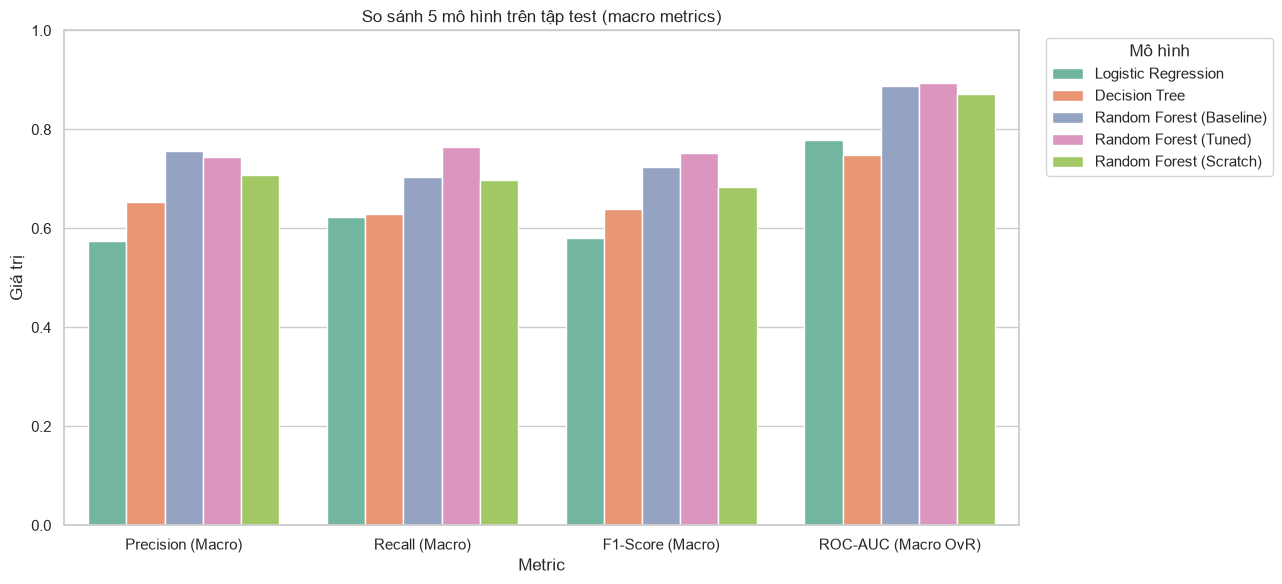

In [19]:
# ******************************************************************
# Purpose: Vẽ biểu đồ cột nhóm so sánh 4 chỉ số cốt lõi (Macro Precision,
#          Macro Recall, Macro F1, Macro ROC-AUC) của cả 5 mô hình.
# Inputs: comparison_results: DataFrame kết quả từ bước đánh giá.
# Returns: None (hiển thị và lưu vào results/visualize).
# Author: Sirinne
# last modified:
# ******************************************************************
core_metrics = ["Precision (Macro)", "Recall (Macro)", "F1-Score (Macro)", "ROC-AUC (Macro OvR)"]
chart_data = (
    comparison_results[core_metrics]
    .round(4)
    .reset_index()
    .melt(id_vars="Model", var_name="Metric", value_name="Score")
)

fig, ax = plt.subplots(figsize=(13, 6))
sns.barplot(data=chart_data, x="Metric", y="Score", hue="Model", palette="Set2", ax=ax)
ax.set_title("So sánh 5 mô hình trên tập test (macro metrics)")
ax.set_ylim(0, 1)
ax.set_ylabel("Giá trị")
ax.legend(title="Mô hình", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(RESULTS_VISUALIZE_DIR / "model_metrics_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

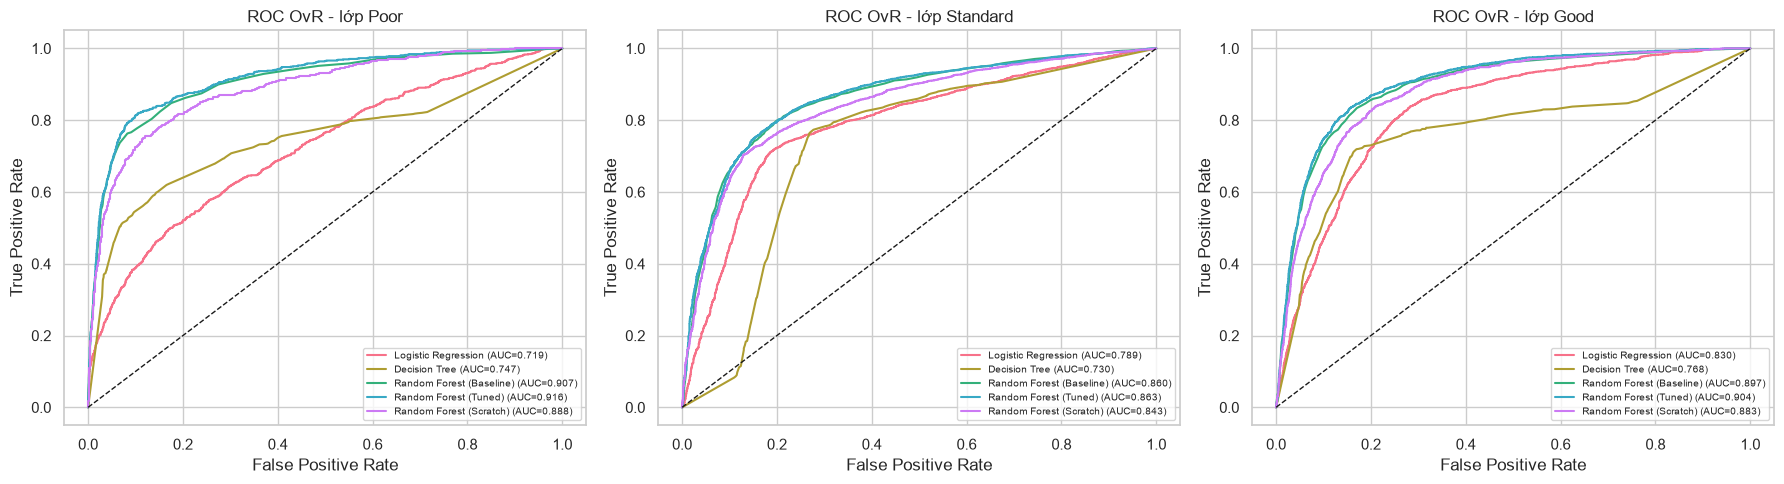

In [20]:
# ******************************************************************
# Purpose: Vẽ đường cong ROC One-vs-Rest cho từng lớp (Poor, Standard,
#          Good), mỗi lớp một panel, mỗi mô hình một đường cong + AUC.
# Inputs: model_predictions: dict dự báo/xác suất của 5 mô hình.
#         y_test: nhãn thật của tập test.
# Returns: None (hiển thị và lưu vào results/visualize).
# Author: Sirinne
# last modified:
# ******************************************************************
figure, axes = plt.subplots(1, 3, figsize=(18, 5))
model_colors = sns.color_palette("husl", len(model_predictions))

for class_index, class_name in enumerate(CLASS_NAMES):
    ax = axes[class_index]
    binary_labels = (y_test == class_index).astype(int)
    for color, (model_name, (_, probabilities, _)) in zip(model_colors, model_predictions.items()):
        false_positive_rate, true_positive_rate, _ = roc_curve(
            binary_labels, probabilities[:, class_index]
        )
        ax.plot(
            false_positive_rate,
            true_positive_rate,
            color=color,
            label=f"{model_name} (AUC={auc(false_positive_rate, true_positive_rate):.3f})",
        )
    ax.plot([0, 1], [0, 1], "k--", linewidth=1)
    ax.set_title(f"ROC OvR - lớp {class_name}")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(fontsize=7, loc="lower right")

plt.tight_layout()
plt.savefig(RESULTS_VISUALIZE_DIR / "multiclass_roc_curves.png", dpi=150)
plt.show()

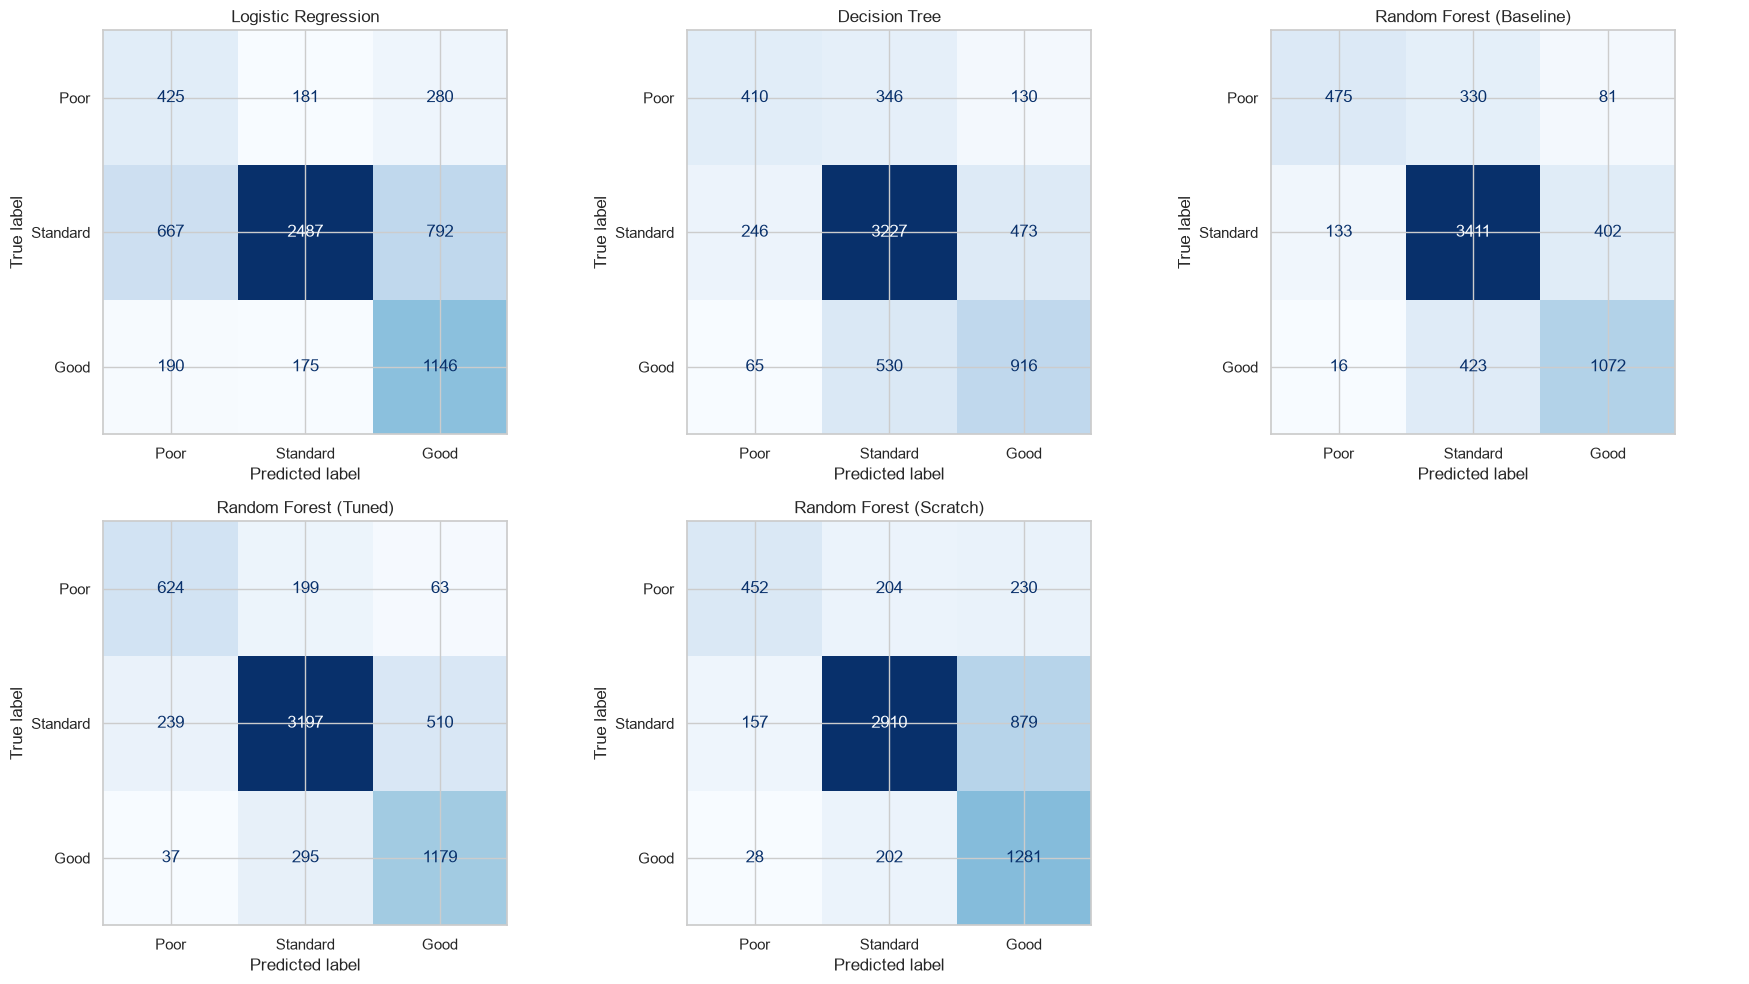

In [21]:
# ******************************************************************
# Purpose: Vẽ ma trận nhầm lẫn 3x3 cho cả 5 mô hình trên tập test để thấy
#          rõ sự đánh đổi giữa các lớp (đặc biệt là nhầm Poor/Standard).
# Inputs: model_predictions: dict nhãn dự báo của 5 mô hình.
#         y_test: nhãn thật của tập test.
# Returns: None (hiển thị và lưu vào results/visualize).
# Author: Sirinne
# last modified:
# ******************************************************************
figure, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (model_name, (prediction, _, _)) in zip(axes.ravel(), model_predictions.items()):
    display_matrix = confusion_matrix(y_test, prediction, labels=[0, 1, 2])
    ConfusionMatrixDisplay(confusion_matrix=display_matrix, display_labels=CLASS_NAMES).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False
    )
    ax.set_title(model_name)
axes.ravel()[-1].axis("off")

plt.tight_layout()
plt.savefig(RESULTS_VISUALIZE_DIR / "confusion_matrices_comparison.png", dpi=150)
plt.show()

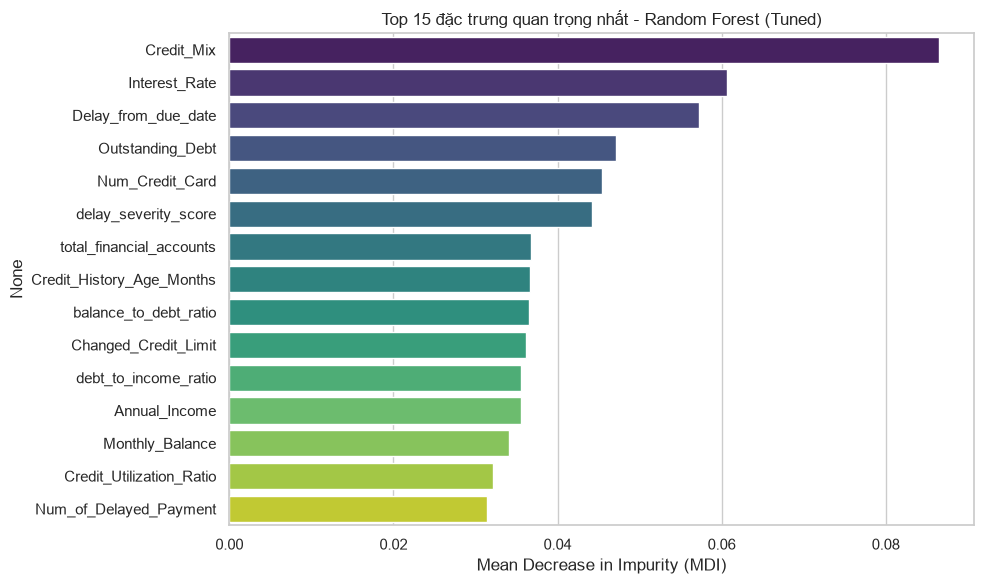

,importance
Credit_Mix,0.0864
Interest_Rate,0.0606
Delay_from_due_date,0.0572
Outstanding_Debt,0.0472
Num_Credit_Card,0.0455
delay_severity_score,0.0442
total_financial_accounts,0.0367
Credit_History_Age_Months,0.0367
balance_to_debt_ratio,0.0366
Changed_Credit_Limit,0.0362


In [22]:
# ******************************************************************
# Purpose: Trích xuất và vẽ Top 15 đặc trưng quan trọng nhất (MDI) của
#          Random Forest tuned để diễn giải mô hình.
# Inputs: random_forest_tuned: mô hình RF tốt nhất đã fit.
#         X_train_tree: DataFrame đặc trưng dùng huấn luyện (giữ tên cột).
# Returns: importances: Series độ quan trọng theo tên đặc trưng (top 15).
# Author: Sirinne
# last modified:
# ******************************************************************
importances = (
    pd.Series(random_forest_tuned.feature_importances_, index=X_train_tree.columns)
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(10, 6))
sns.barplot(x=importances.values, y=importances.index, hue=importances.index,
            legend=False, palette="viridis")
plt.title("Top 15 đặc trưng quan trọng nhất - Random Forest (Tuned)")
plt.xlabel("Mean Decrease in Impurity (MDI)")
plt.tight_layout()
plt.savefig(RESULTS_VISUALIZE_DIR / "rf_feature_importance.png", dpi=150)
plt.show()

display(importances.round(4).to_frame("importance"))

### Kết luận & thảo luận

1. **So sánh tổng thể.** Bảng `results/run/credit_score_model_comparison.csv` và biểu đồ `model_metrics_comparison.png` cho thấy thứ hạng các mô hình theo **Macro F1** và **ROC-AUC (Macro OvR)**. Nhìn chung, các mô hình dựa trên cây (Random Forest) thường tốt hơn Logistic Regression ở bài toán này vì ranh giới giữa 3 lớp mang tính phi tuyến, nhiều ngưỡng rời rạc (ví dụ `Interest_Rate`, `Delay_from_due_date`).
2. **Tác dụng của việc tune trọng số (`class_weight`).** Random Forest baseline (không cân bằng) có xu hướng thiên về `Standard` → Macro Recall thấp vì bỏ sót `Poor` và `Good`. Khi đưa `class_weight` (kể cả dict tự đặt cho `Poor`/`Good`) vào không gian tìm kiếm và tối ưu thêm hệ số nhân xác suất trên validation, Macro F1 tăng rõ rệt nhờ cân bằng lại Precision/Recall giữa các lớp — đây chính là bằng chứng định lượng cho trade-off được thảo luận trong EDA.
3. **Random Forest tự viết vs thư viện.** `RandomForestScratch` dùng đúng Weighted Gini + bagging + random feature subset, đạt Macro F1 trong cùng khoảng với RF baseline của sklearn nhưng thường thấp hơn RF tuned (vì fewer trees, ngưỡng chia xấp xỉ lượng tử và không có tối ưu Cython). Khoảng cách này phản ánh đúng giá trị của việc tối ưu ở cấp thư viện; đồng thời khẳng định phần cài đặt tay **học được tín hiệu thật** (vượt xa baseline đoán toàn `Standard` ở cell self-check).
4. **Đọc ma trận nhầm lẫn.** Lỗi phổ biến nhất thường là nhầm lẫn `Poor` ↔ `Standard` (hai lớp này có hành vi gần nhau hơn so với `Good`). Precision lớp `Poor` cao cho biết trong các ca báo rủi ro cao thì bao nhiêu là đúng; Recall lớp `Poor` cho biết đã bắt được bao nhiêu khách hàng thực sự rủi ro — trong bài toán chấm điểm tín dụng, đây là cặp chỉ số cần cân bằng theo chi phí nghiệp vụ (FN của `Poor` thường đắt hơn FP).
5. **Đặc trưng quan trọng (top 15).** Các đặc trưng tổng hợp từ feature engineering (tỷ lệ nợ/thu nhập, `delay_severity_score`, `Credit_History_Age_Months`, `Credit_Mix`, `spending_level`...) thường chiếm vị trí cao — chứng tỏ việc tạo đặc trưng nghiệp vụ mang lại lợi ích rõ rệt so với dùng 20 cột gốc.

**Giới hạn:** (1) file không còn `Customer_ID` nên không thể chia theo nhóm khách hàng — có thể tồn tại trùng khách hàng giữa train/val/test, do đó các chỉ số test có thể hơi lạc quan; (2) chia ngẫu nhiên theo dòng là bắt buộc; (3) `Credit_Score` có thứ tự tự nhiên nhưng được xử lý như phân loại 3 lớp rời rạc theo yêu cầu bài toán — nếu muốn khai thác thứ tự, có thể thử ordinal classification hoặc gom `Poor` thành nhị phân; (4) bản RF tự viết Deliberately đơn giản (không OOB, không song song) nên thời gian fit lớn hơn sklearn despite fewer trees.

## Artifacts được tạo ra khi chạy notebook này

| File | Nội dung |
|---|---|
| `source/logs/train_credit_score_rf_<timestamp>.txt` | Log đầy đủ quá trình chạy (thời gian, tham số, chỉ số từng mô hình) |
| `results/run/credit_score_best_params.json` | Siêu tham số RF tuned, cấu hình LR/DT được chọn |
| `results/run/credit_score_model_comparison.csv` | Bảng so sánh đầy đủ Precision/Recall/F1/ROC-AUC của 5 mô hình |
| `results/visualize/eda_*.png` | Biểu đồ EDA (phân phối nhãn, categorical, outliers, heatmap) |
| `results/visualize/model_metrics_comparison.png` | So sánh macro metrics giữa 5 mô hình |
| `results/visualize/multiclass_roc_curves.png` | Đường cong ROC One-vs-Rest theo lớp |
| `results/visualize/confusion_matrices_comparison.png` | Ma trận nhầm lẫn của 5 mô hình |
| `results/visualize/rf_feature_importance.png` | Top 15 đặc trưng quan trọng (RF tuned) |